# The 2D Ising model with Metropolis Monte Carlo

This notebook simulates the two-dimensional Ising model on an $L \times L$ lattice and reproduces Onsager's exact result for the magnetisation.

**Steps**

1. Build a lattice of spins and compute each site's neighbour sum.
2. Write the Metropolis update, using a checkerboard so that NumPy can update half the lattice at once.
3. Check equilibration at a low and a high temperature.
4. Scan the temperature and compare $|m|(T)$ with the exact curve.
5. Repeat the scan on larger lattices to see the finite-size effects shrink.
6. Look at snapshots of the lattice below, near and above the critical temperature.

**Result.** The simulation reproduces Onsager's exact magnetisation below the critical temperature $T_c \approx 2.27$ and shows the phase transition there. Above $T_c$ a finite lattice keeps a non-zero magnetisation, which shrinks as the lattice grows.

## The model

Each site $i$ carries a spin $s_i = \pm 1$. The energy of a configuration is

$$E = -J \sum_{\langle i j \rangle} s_i s_j ,$$

where the sum runs over all pairs of nearest neighbours. With $J > 0$ (a ferromagnet), every parallel pair contributes $-J$ and every antiparallel pair $+J$, so aligned spins have lower energy. We use $J = 1$, $k_B = 1$ and periodic boundaries: the right edge wraps round to the left edge, and the top to the bottom.

At temperature $T$ the probability of a configuration $s$ is the Boltzmann weight

$$P(s) \propto e^{-E(s)/T} .$$

Averages such as the magnetisation are sums over all $2^{L^2}$ configurations. For $L = 32$ that is $2^{1024}$ terms, far too many to add up. Monte Carlo instead **samples** configurations with probability $P(s)$ and averages over the samples.

## Setup

`rng` is a seeded random number generator. All randomness in the notebook comes from it, so the whole notebook gives the same results every time it is run from the top with the same NumPy version. Other NumPy versions can produce a different random sequence, which changes the numbers slightly but not the conclusions.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

## 1. The lattice

A lattice is an $L \times L$ array of $+1$ and $-1$. A random lattice has roughly equal numbers of each, so its mean is close to 0.

In [2]:
def make_lattice(L: int, rng: np.random.Generator) -> np.ndarray:
    """Return an L x L lattice of random spins, each +1 or -1."""
    return rng.choice([-1, 1], size=(L, L))

In [3]:
spins = make_lattice(4, rng)
print(spins)
print(spins.shape)                        # (4, 4)
print(make_lattice(100, rng).mean())      # close to 0

[[-1  1  1 -1]
 [-1  1 -1  1]
 [-1 -1  1  1]
 [ 1  1  1  1]]
(4, 4)
-0.0122


## 2. The neighbour sum

Every site has four neighbours: up, down, left and right. `np.roll` shifts the whole array by one place along an axis and wraps the edge round, which is exactly the periodic boundary. Adding the four shifted copies gives, at every site, the sum of its four neighbours:

$$n_i = \sum_{j \in \text{nb}(i)} s_j \in \{-4, -2, 0, 2, 4\} .$$

In [4]:
def neighbour_sum(spins: np.ndarray) -> np.ndarray:
    """Return an array, same shape as spins, holding the sum of each site's 4 neighbours."""
    return (np.roll(spins, 1, axis=0) + np.roll(spins, -1, axis=0)
            + np.roll(spins, 1, axis=1) + np.roll(spins, -1, axis=1))

**Check:** on a lattice of all $+1$, every site has four up neighbours, so every entry should be 4.

In [5]:
print(neighbour_sum(np.ones((4, 4), dtype=int)))   # all 4s
print(neighbour_sum(spins).shape)                   # (4, 4)

[[4 4 4 4]
 [4 4 4 4]
 [4 4 4 4]
 [4 4 4 4]]
(4, 4)


## 3. The Metropolis rule

Flipping spin $s_i$ changes only the four bonds that touch it. Before the flip they contribute $-J s_i n_i$, after it $+J s_i n_i$, so

$$\Delta E = 2 J s_i n_i .$$

The Metropolis rule accepts the flip with probability

$$p = \min\left(1, e^{-\Delta E / T}\right) .$$

A flip that lowers the energy ($\Delta E \le 0$) is always accepted; one that raises it is accepted with probability $e^{-\Delta E/T}$. In code: draw a random number $r \in [0, 1)$ and flip if $r < e^{-\Delta E/T}$. This covers both cases, because $e^{-\Delta E/T} \ge 1$ whenever $\Delta E \le 0$.

**Why it samples the Boltzmann distribution.** The rule satisfies detailed balance: for any two configurations $a$ and $b$ that differ by one flip, $P(a)\,p(a \to b) = P(b)\,p(b \to a)$. So once the probabilities are Boltzmann, an update keeps them Boltzmann. And at any $T > 0$ every flip has a non-zero chance of being accepted, so any configuration can be reached from any other. Together these mean that, after enough updates, the lattice is in configuration $s$ with probability $P(s)$, whatever the start.

## 4. The checkerboard

To use NumPy we want to test many spins at once. But two **neighbouring** spins must not be updated at the same time: each one's $\Delta E$ assumes the other stays put, so if both flip, the acceptance decisions use the wrong energy and the result is no longer the Boltzmann distribution.

The fix is to colour the lattice like a checkerboard. A site $(i, j)$ is black if $i + j$ is even, white otherwise. One step to a neighbour changes $i + j$ by 1, so **every neighbour of a black site is white**. No two black sites interact, and updating all black sites at once gives the same result as updating them one by one. Then the same for white.

With periodic boundaries $L$ must be even. Wrapping from column $L-1$ to column 0 changes $i + j$ by $L - 1$, which is odd only when $L$ is even.

In [6]:
def checkerboard_masks(L: int):
    """Return two boolean L x L masks, black and white, such that no two sites of the same colour are neighbours."""
    if L % 2 != 0:
        raise ValueError("L must be even for the checkerboard to work with periodic boundaries.")
    i, j = np.indices((L, L))
    black = (i + j) % 2 == 0
    white = ~black
    return black, white

**Checks:** half the sites are black, every site has exactly one colour, and no black site has a black neighbour. The last check includes the wrap-around neighbours at the edges.

In [7]:
black, white = checkerboard_masks(4)
print(black.astype(int))
print(black.sum() == 8, np.all(black != white))                # True True
print(np.all(neighbour_sum(black.astype(int))[black] == 0))    # True

[[1 0 1 0]
 [0 1 0 1]
 [1 0 1 0]
 [0 1 0 1]]
True True
True


## 5. One sweep

A **sweep** is one update of the black sites followed by one update of the white sites, so every spin gets exactly one chance to flip.

For each colour:

1. compute the neighbour sums and $\Delta E$ for every site, using the current lattice;
2. draw a fresh random number for every site and decide which sites accept;
3. flip only the sites that are of this colour **and** accepted: `mask & accept`.

The neighbour sums are recomputed before the white update, because flipping black spins changes the neighbours of the white ones. `spins[...] *= -1` changes the array in place, so the caller's `spins` is updated.

In [8]:
def sweep(spins: np.ndarray, T: float, rng: np.random.Generator,
          black: np.ndarray, white: np.ndarray, J: float = 1.0) -> np.ndarray:
    """One Metropolis sweep: update all black sites, then all white sites. Changes spins in place."""
    for mask in (black, white):
        nb = neighbour_sum(spins)
        dE = 2 * J * spins * nb
        accept = rng.random(spins.shape) < np.exp(-dE / T)
        spins[mask & accept] *= -1
    return spins

## 6. What we measure

**Energy per spin.** The energy divided by the number of spins $N = L^2$, so that it does not depend on the lattice size. `np.sum(spins * neighbour_sum(spins))` counts every bond twice (once from each end), hence the division by 2. A fully aligned lattice has 2 bonds per spin, each $-J$, so $E/N = -2J$.

**Magnetisation per spin.** The average spin,

$$m = \frac{1}{N} \sum_i s_i ,$$

between $-1$ (all down) and $+1$ (all up). It is the **order parameter**: for an infinite lattice it is non-zero in the ordered phase and zero in the disordered one. On a finite lattice the Boltzmann distribution gives every configuration and its fully flipped copy the same weight, so the exact average of $m$ is 0 at every temperature, even when the lattice is ordered. We therefore average $|m|$, the standard quantity to compare with the spontaneous magnetisation.

In [9]:
def energy_per_spin(spins: np.ndarray, J: float = 1.0) -> float:
    """Energy of the lattice divided by the number of spins."""
    return -J * np.sum(spins * neighbour_sum(spins)) / 2 / spins.size

def abs_magnetisation(spins: np.ndarray) -> float:
    """Absolute value of the mean spin."""
    return abs(spins.mean())

## 7. Equilibration at T = 1 and T = 5

A run has two phases:

- **Equilibration.** The first sweeps carry the lattice from its starting configuration to a typical one at temperature $T$. These sweeps are not yet Boltzmann samples, so they are thrown away.
- **Measurement.** After that, each sweep gives a configuration drawn from the Boltzmann distribution. Averaging $E/N$ and $|m|$ over these sweeps estimates their equilibrium values.

**Why start from all spins up.** A random start at low $T$ can freeze into two stripes of opposite spin that wrap around the periodic lattice. A straight wall cannot shorten by moving, so no single flip lowers the energy, and the stripes can survive for many thousands of sweeps. On a $32 \times 32$ lattice they show up as $E/N \approx -1.875$, with $|m|$ anywhere between 0 and 1 depending on the widths of the stripes. An ordered start has no walls. At high $T$ the ordered start melts within a few sweeps, so it works there too.

The x-axis below is logarithmic, so the first few sweeps are visible next to the long flat part.

**Expected:** at $T = 1$, $E/N \approx -1.997$ and $|m| \approx 0.999$ (exact for an infinite lattice: $-1.9972$ and $0.9993$). At $T = 5$, $E/N \approx -0.43$ (exact: $-0.428$) and $|m| \approx 0.04$; the exact value is 0, and a finite lattice keeps a few hundredths.

T = 1.0: last 4000 sweeps  E per spin = -1.997,  |m| = 0.999


T = 5.0: last 4000 sweeps  E per spin = -0.429,  |m| = 0.043


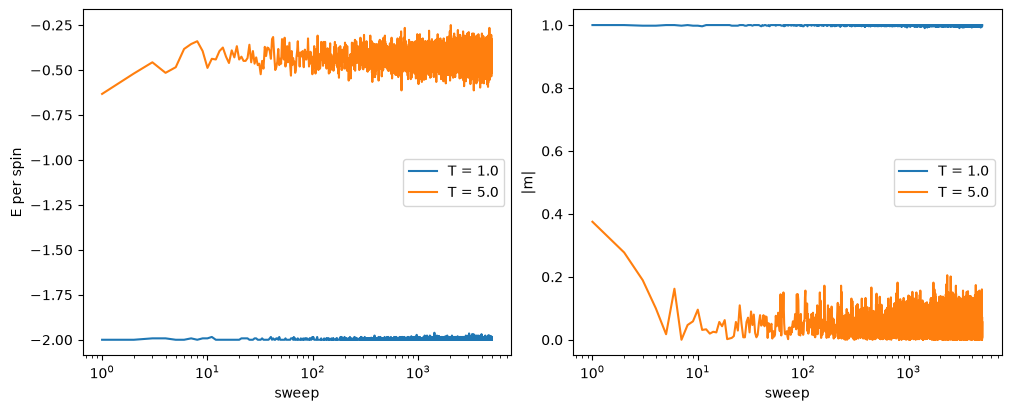

In [10]:
L = 32
n_sweeps = 5000
n_equil = 1000          # sweeps thrown away before averaging
black, white = checkerboard_masks(L)
sweeps = np.arange(1, n_sweeps + 1)

fig, ax = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for T in (1.0, 5.0):
    spins = np.ones((L, L), dtype=int)      # start with all spins up
    Es, ms = [], []
    for _ in range(n_sweeps):
        sweep(spins, T, rng, black, white)
        Es.append(energy_per_spin(spins))
        ms.append(abs_magnetisation(spins))
    ax[0].plot(sweeps, Es, label=f"T = {T}")
    ax[1].plot(sweeps, ms, label=f"T = {T}")
    print(f"T = {T}: last {n_sweeps - n_equil} sweeps  "
          f"E per spin = {np.mean(Es[n_equil:]):.3f},  |m| = {np.mean(ms[n_equil:]):.3f}")

for a, name in zip(ax, ("E per spin", "|m|")):
    a.set_xscale("log")
    a.set_xlabel("sweep")
    a.set_ylabel(name)
    a.legend()
plt.show()

**Reading the plot.** At $T = 1$ the curves are flat from the first sweep: the all-up lattice is already typical, and thermal flips only knock out a spin now and then, which is why $|m|$ is 0.999 and not exactly 1. At $T = 5$ the order is gone within about 5 sweeps, and both curves then fluctuate around their equilibrium values. Throwing away 1,000 sweeps is therefore far more than needed here.

The orange band looks wider on the right only because the log axis packs more sweeps into the same width there.

Consecutive sweeps are correlated: one sweep changes only part of the lattice, so sweep 101 resembles sweep 100. This does not bias the averages, but 4,000 sweeps are worth fewer than 4,000 independent samples. It matters for error bars, which this notebook does not compute.

## 8. Onsager's exact result

Onsager solved the 2D Ising model exactly in 1944, and Yang derived its magnetisation in 1952. For an **infinite** lattice in zero field, the critical temperature is

$$T_c = \frac{2J}{\ln(1 + \sqrt{2})} \approx 2.269 ,$$

and the spontaneous magnetisation is

$$|m| = \left(1 - \sinh^{-4}(2J/T)\right)^{1/8} \quad \text{for } T < T_c, \qquad |m| = 0 \quad \text{for } T \ge T_c .$$

Near $T_c$ this behaves like $(T_c - T)^{1/8}$: the curve stays high and then drops to zero with a vertical tangent. The exponent $1/8$ is the critical exponent $\beta$ of the 2D Ising universality class.

The function evaluates the formula only below $T_c$. Above $T_c$, $\sinh^{-4}(2J/T) > 1$, so the bracket is negative and its 1/8 power would give `nan`. Those entries keep the value 0 from `np.zeros_like`.

In [11]:
def onsager_magnetisation(T: np.ndarray, J: float = 1.0) -> np.ndarray:
    """Exact spontaneous magnetisation of the infinite 2D Ising model."""
    T = np.asarray(T, dtype=float)
    m = np.zeros_like(T)
    below = T < 2 * J / np.log(1 + np.sqrt(2))      # below the critical temperature
    m[below] = (1 - np.sinh(2 * J / T[below]) ** -4) ** (1 / 8)
    return m

## 9. Temperature scan

The same two-phase run at 26 temperatures from 1.0 to 3.5, in steps of 0.1: at each temperature, 1,000 sweeps are thrown away and 4,000 are averaged. That gives one value of $\langle E/N \rangle$ and one of $\langle |m| \rangle$ per temperature.

The lattice is created once, all spins up, and **never reset**. Each temperature starts from the lattice the previous one ended with. The equilibrium state at $T + 0.1$ is usually close to the one at $T$, so equilibration is short. Near $T_c$ the change is larger, but 1,000 sweeps is still many times the time the lattice needs to forget its earlier state there (about 40 sweeps, section 11). And the run never starts from a random lattice at low $T$, so no stripes.

This takes 15 to 30 seconds.

In [12]:
L = 32
n_equil = 1000
n_measure = 4000
temperatures = np.linspace(1.0, 3.5, 26)
black, white = checkerboard_masks(L)

spins = np.ones((L, L), dtype=int)          # start ordered at the lowest temperature
E_mean, m_mean = [], []
for T in temperatures:                      # each T starts from the last lattice of the previous T
    for _ in range(n_equil):
        sweep(spins, T, rng, black, white)
    Es, ms = [], []
    for _ in range(n_measure):
        sweep(spins, T, rng, black, white)
        Es.append(energy_per_spin(spins))
        ms.append(abs_magnetisation(spins))
    E_mean.append(np.mean(Es))
    m_mean.append(np.mean(ms))
    print(f"T = {T:.2f}   E per spin = {E_mean[-1]:.3f}   |m| = {m_mean[-1]:.3f}")

T = 1.00   E per spin = -1.997   |m| = 0.999


T = 1.10   E per spin = -1.994   |m| = 0.998


T = 1.20   E per spin = -1.988   |m| = 0.997


T = 1.30   E per spin = -1.980   |m| = 0.995


T = 1.40   E per spin = -1.968   |m| = 0.991


T = 1.50   E per spin = -1.951   |m| = 0.986


... (16 outputs left out)

T = 3.20   E per spin = -0.746   |m| = 0.074


T = 3.30   E per spin = -0.713   |m| = 0.068


T = 3.40   E per spin = -0.686   |m| = 0.064


T = 3.50   E per spin = -0.660   |m| = 0.063


## 10. Comparison with the exact curve

The exact curve is a formula, so it is evaluated at 500 temperatures to draw a smooth line. The simulation gives 26 points, drawn as markers. The grey vertical line marks $T_c$.

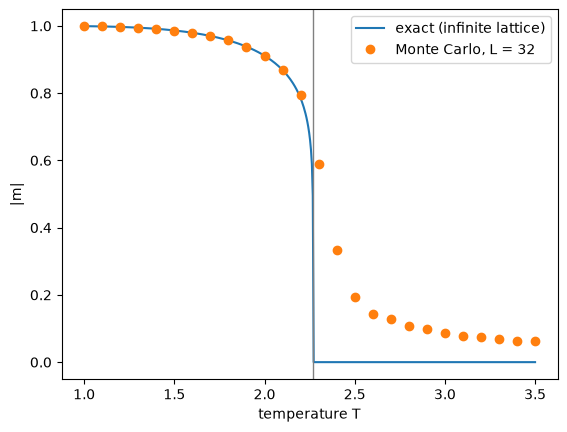

In [13]:
T_fine = np.linspace(1.0, 3.5, 500)
Tc = 2 / np.log(1 + np.sqrt(2))

plt.plot(T_fine, onsager_magnetisation(T_fine), label="exact (infinite lattice)")
plt.plot(temperatures, m_mean, "o", label=f"Monte Carlo, L = {L}")
plt.axvline(Tc, color="gray", linewidth=1)
plt.xlabel("temperature T")
plt.ylabel("|m|")
plt.legend()
plt.show()

**Reading the plot.**

- **Below $T_c$** the simulation reproduces the exact curve: $|m| = 0.999$ at $T = 1$ (exact 0.9993), 0.911 at $T = 2$ (exact 0.9113).
- **The drop** happens between $T = 2.2$ and $2.4$, around $T_c = 2.269$. The energy rises fastest in the same interval, which is where the specific heat peaks.
- **Above $T_c$** the points do not fall to 0. This is a finite-size effect, not an error. The exact curve is for an infinite lattice. On a $32 \times 32$ lattice, random imbalance alone leaves $|m|$ at a few hundredths, and just above $T_c$ the correlated clusters are still comparable to the lattice size, so the drop is smoothed out. The next section tests this by repeating the scan on larger lattices.

## 11. Larger lattices

If the gap above $T_c$ is a finite-size effect, it must shrink as the lattice grows. This section repeats the scan for $L = 64$ and $L = 128$.

The scan is the one from section 9, wrapped in a function so that it can be called for any lattice size. It records only $|m|$.

In [14]:
def scan(L: int, temperatures: np.ndarray, n_equil: int, n_measure: int,
         rng: np.random.Generator) -> np.ndarray:
    """Return the mean |m| at each temperature for an L x L lattice.

    The lattice starts with all spins up at the first temperature and is carried
    over from each temperature to the next, as in section 9.
    """
    black, white = checkerboard_masks(L)
    spins = np.ones((L, L), dtype=int)
    m_mean = []
    for T in temperatures:
        for _ in range(n_equil):
            sweep(spins, T, rng, black, white)
        ms = []
        for _ in range(n_measure):
            sweep(spins, T, rng, black, white)
            ms.append(abs_magnetisation(spins))
        m_mean.append(np.mean(ms))
    return np.array(m_mean)

**More sweeps for larger lattices.** Near $T_c$ the correlated clusters grow with the lattice, and a larger cluster takes more sweeps to change. A measure of this is the integrated autocorrelation time of $|m|$, roughly the number of sweeps the lattice needs to forget its earlier state. At $T = 2.3$ it is about 40 sweeps for $L = 32$, about 190 for $L = 64$ and about 360 for $L = 128$ (measured in separate runs of 200,000 sweeps). With the same number of sweeps, the larger lattices would give fewer independent samples there. So the number of sweeps grows with $L$: twice as many for $L = 64$ and four times as many for $L = 128$.

The $L = 32$ result is taken from section 9. **This cell takes about 4 to 5 minutes**, most of it for $L = 128$.

In [15]:
import time

m_by_size = {32: np.array(m_mean)}             # the L = 32 scan from section 9
for size in (64, 128):
    factor = size // 32                        # 2 for L = 64, 4 for L = 128
    start = time.time()
    m_by_size[size] = scan(size, temperatures, 1000 * factor, 4000 * factor, rng)
    print(f"L = {size}: {1000 * factor} + {4000 * factor} sweeps per temperature, {time.time() - start:.0f} s")

L = 64: 2000 + 8000 sweeps per temperature, 37 s


L = 128: 4000 + 16000 sweeps per temperature, 216 s


The table lists the values around $T_c$. The plot shows all three sizes against the exact curve.

   T    L = 32   L = 64   L = 128   exact
 2.00    0.911    0.911     0.911   0.911
 2.10    0.869    0.869     0.869   0.869
 2.20    0.795    0.790     0.788   0.785
 2.30    0.590    0.421     0.292   0.000
 2.40    0.332    0.175     0.084   0.000
 2.50    0.195    0.104     0.049   0.000
 2.60    0.142    0.076     0.037   0.000


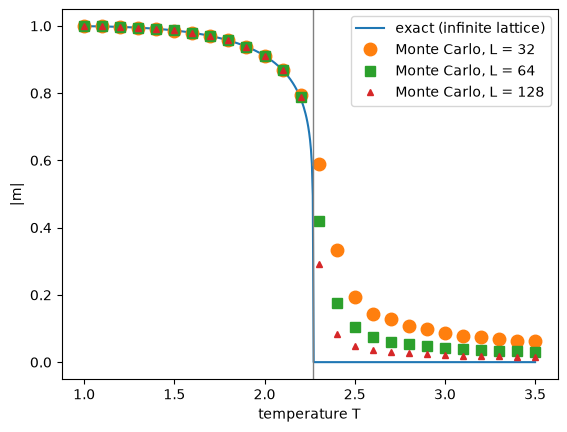

In [16]:
exact = onsager_magnetisation(temperatures)
print("   T    L = 32   L = 64   L = 128   exact")
for k in range(10, 17):                        # T = 2.0 to 2.6
    print(f"{temperatures[k]:5.2f}   {m_by_size[32][k]:6.3f}   {m_by_size[64][k]:6.3f}   "
          f"{m_by_size[128][k]:7.3f}   {exact[k]:5.3f}")

plt.plot(T_fine, onsager_magnetisation(T_fine), label="exact (infinite lattice)")
for size, marker, markersize in zip((32, 64, 128), ("o", "s", "^"), (9, 7, 5)):
    plt.plot(temperatures, m_by_size[size], marker, markersize=markersize, label=f"Monte Carlo, L = {size}")
plt.axvline(Tc, color="gray", linewidth=1)
plt.xlabel("temperature T")
plt.ylabel("|m|")
plt.legend()
plt.show()

**Reading the plot.**

- **Below $T_c$** all three sizes agree with the exact curve to within about 1 %, so their markers lie on top of each other.
- **Well above $T_c$** $|m|$ roughly halves each time $L$ doubles: about 0.20, 0.10 and 0.05 at $T = 2.5$. A disordered lattice only has the random imbalance of its $N = L^2$ spins, which falls as $1/\sqrt{N} = 1/L$ and vanishes for an infinite lattice. Just above $T_c$, at $T = 2.3$, it falls more slowly (0.59, 0.42, 0.29). There the exact correlation length is about 42 sites, comparable to the lattice sizes, so a single lattice holds only a few independent regions. At $T = 2.4$ it is already down to about 10 sites.
- **The drop becomes steeper** as $L$ grows. Between $T = 2.2$ and $2.4$, $|m|$ falls from 0.80 to 0.33 for $L = 32$, from 0.79 to 0.18 for $L = 64$ and from 0.79 to 0.08 for $L = 128$.
- **The points approach the exact curve** as $L$ grows. This confirms that the gap in section 10 is a finite-size effect.

The point at $T = 2.3$ is the least certain one. It is closest to $T_c$, where consecutive sweeps are most correlated, and its statistical error is about $\pm 0.03$ to $\pm 0.04$ for all three sizes, estimated from the autocorrelation times above.

## 12. Snapshots

One equilibrated configuration at three temperatures on a $128 \times 128$ lattice, the largest size from section 11, so that the structure is visible. Each lattice starts with all spins up and runs for 3,000 sweeps before the picture is taken. White is $+1$, black is $-1$. This takes about 5 seconds.

- **$T = 1.5$, below $T_c$:** almost all one colour, with isolated flipped spins that appear and disappear.
- **$T = 2.3$, just above $T_c$:** clusters of every size, from single spins up to a large fraction of the lattice. The exact correlation length here is about 42 sites. At $T_c$ itself the energy cost of a domain wall is exactly balanced by the number of ways to draw it (the interface tension vanishes), so walls of every length appear.
- **$T = 3.5$, well above $T_c$:** the exact correlation length is only about 1.4 sites, so the pattern is close to random noise, with only small clusters.

The big clusters near $T_c$ also explain **critical slowing down**: a sweep flips individual spins, mostly at cluster edges, so a large cluster changes only over many sweeps.

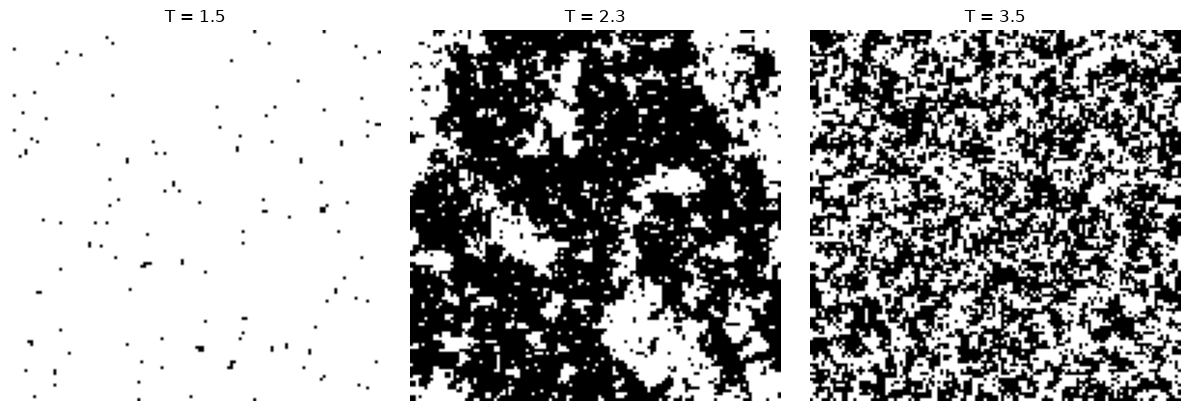

In [17]:
L_big = 128
n_equil_big = 3000
black_big, white_big = checkerboard_masks(L_big)

fig, ax = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
for a, T in zip(ax, (1.5, 2.3, 3.5)):
    spins_big = np.ones((L_big, L_big), dtype=int)
    for _ in range(n_equil_big):
        sweep(spins_big, T, rng, black_big, white_big)
    a.imshow(spins_big, cmap="gray", vmin=-1, vmax=1)   # white = +1, black = -1
    a.set_title(f"T = {T}")
    a.axis("off")
plt.show()